# Friday Night Planner
Fuzzy control system that matches the user's input with matching events.

1. The user states preferences and how important each one is (1–10)
2. For every event, fit scores (0–10) measure how well the event satisfies each preference
3. For each criterion, a small fuzzy system combines fit and importance into a contribution (fuzzy rules)
4. The six contributions are averaged into one score
5. A final fuzzy system maps this score to a match in percent

## 1. Imports

In [1]:
from datetime import datetime

import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl

## 2. User preferences
What does the user want, and how much do they care about it?

In [20]:
userDate = "2026-11-06"
userTime = "19:00"
maxDistance = 5
maxBudget = 50
userGroupSize = 2
userEnergyLevel = 7

# Importance ratings 1 (low) - 10 (high)
dateImportance = 10
timeImportance = 8
distanceImportance = 5
budgetImportance = 10
groupSizeImportance = 6
energyImportance = 7

## 3. Event data
Each event has a date, start time, distance (km), price (CHF), capacity (people) and an energy level (0–10).

In [22]:
events = [
    {"name": "Rock Concert",        "date": "2026-11-06", "time": "19:00", "distance": 10, "price": 45, "capacity": 200, "energy": 9},
    {"name": "Cinema Night",        "date": "2026-11-06", "time": "20:00", "distance": 5,  "price": 25, "capacity": 20,  "energy": 2},
    {"name": "Hiking Trip",         "date": "2026-11-07", "time": "10:00", "distance": 30, "price": 10, "capacity": 15,  "energy": 8},
    {"name": "Dinner with Friends", "date": "2026-11-06", "time": "19:30", "distance": 15, "price": 20, "capacity": 8,   "energy": 5},
    {"name": "Escape Room",         "date": "2026-11-06", "time": "18:00", "distance": 25, "price": 60, "capacity": 6,   "energy": 6},
]

## 4. Fit functions
Each function returns a score between 0 and 10

In [23]:
def calculate_date_fit(user_date, event_date):
    """Loses 2.5 points per day of difference"""
    user_date = datetime.strptime(user_date, "%Y-%m-%d").date()
    event_date = datetime.strptime(event_date, "%Y-%m-%d").date()

    difference = abs((user_date - event_date).days)
    return max(0, 10 - difference * 2.5)


def calculate_time_fit(user_time, event_time):
    """Loses 1 point per 30 minutes of difference"""
    user_time = datetime.strptime(user_time, "%H:%M")
    event_time = datetime.strptime(event_time, "%H:%M")

    # Difference in minutes since midnight
    difference = abs(
        (user_time.hour * 60 + user_time.minute)
        - (event_time.hour * 60 + event_time.minute)
    )

    # Account for times around midnight (e.g. 23:30 vs. 00:30 = 60 min)
    difference = min(difference, 1440 - difference)

    return max(0, 10 - difference / 36)


def calculate_distance_fit(max_distance, event_distance):
    """Full score within the maximum distance, then linear decrease to 0 at twice the maximum."""
    if event_distance <= max_distance:
        return 10
    if max_distance <= 0:
        return 0

    return max(0, 10 * (1 - (event_distance - max_distance) / max_distance))


def calculate_budget_fit(max_budget, event_price):
    """Full score within the budget, then linear decrease to 0 at twice the budget."""
    if event_price <= max_budget:
        return 10
    if max_budget <= 0:
        return 0

    return max(0, 10 * (1 - (event_price - max_budget) / max_budget))


def calculate_group_size_fit(user_group_size, event_capacity):
    """Full score if the whole group fits, otherwise proportional to the part that fits"""
    if event_capacity >= user_group_size:
        return 10
    if user_group_size <= 0:
        return 0

    return 10 * event_capacity / user_group_size


def calculate_energy_fit(user_energy, event_energy):
    """Loses 10/9 points per energy level of difference (0 points at a difference of 9)"""
    difference = abs(user_energy - event_energy)
    return max(0, 10 - difference * (10 / 9))


def calculate_event_fits(event):
    """Calculate all six fit scores for one event"""
    return {
        "dateFit":      calculate_date_fit(userDate, event["date"]),
        "timeFit":      calculate_time_fit(userTime, event["time"]),
        "distanceFit":  calculate_distance_fit(maxDistance, event["distance"]),
        "budgetFit":    calculate_budget_fit(maxBudget, event["price"]),
        "groupSizeFit": calculate_group_size_fit(userGroupSize, event["capacity"]),
        "energyFit":    calculate_energy_fit(userEnergyLevel, event["energy"]),
    }

In [24]:
# Quick check: fit scores of the first event
print(calculate_event_fits(events[0]))

{'dateFit': 10.0, 'timeFit': 10.0, 'distanceFit': 0, 'budgetFit': 10, 'groupSizeFit': 10, 'energyFit': 7.777777777777778}


## 5. Fuzzy systems per criterion: fit × importance → contribution
Every criterion gets its own fuzzy system

**Inputs:** fit (0–10) and importance (1–10), each with the terms low / medium / high
**Output:** contribution (0–10), with the terms low / medium / high

| fit \ importance | low | medium | high |
|---|---|---|---|
| **low** | low | low | low |
| **medium** | low | medium | medium |
| **high** | low | high | high |

- A poor fit on an important criterion pulls the match down (low)
- A good fit on an important criterion pushes the match up (high)
- If the criterion is unimportant, the contribution stays low, whatever the fit.

In [25]:
# Rule base: (fit term, importance term) -> contribution term
CONTRIBUTION_RULES = {
    ("low",    "low"):    "low",
    ("low",    "medium"): "low",
    ("low",    "high"):   "low",
    ("medium", "low"):    "low",
    ("medium", "medium"): "medium",
    ("medium", "high"):   "medium",
    ("high",   "low"):    "low",
    ("high",   "medium"): "high",
    ("high",   "high"):   "high",
}


def add_triangular_terms(variable, start):
    """Add the terms low / medium / high to a fuzzy variable"""
    variable['low']    = fuzz.trimf(variable.universe, [start, start, 5])
    variable['medium'] = fuzz.trimf(variable.universe, [start, 5, 10])
    variable['high']   = fuzz.trimf(variable.universe, [5, 10, 10])


def build_contribution_system(name, rules=CONTRIBUTION_RULES):
    """Build the fuzzy system (fit, importance -> contribution) for one criterion"""
    fit          = ctrl.Antecedent(np.linspace(0, 10, 101), f"{name}Fit")
    importance   = ctrl.Antecedent(np.linspace(1, 10, 91),  f"{name}Importance")
    contribution = ctrl.Consequent(np.linspace(0, 10, 101), f"{name}Contribution")

    add_triangular_terms(fit, 0)
    add_triangular_terms(importance, 1)
    add_triangular_terms(contribution, 0)

    rule_list = [
        ctrl.Rule(fit[f] & importance[i], contribution[c])
        for (f, i), c in rules.items()
    ]

    return {
        "fit": fit,
        "importance": importance,
        "contribution": contribution,
        "sim": ctrl.ControlSystemSimulation(ctrl.ControlSystem(rule_list)),
    }


# importance the user gave each criteria
importances = {
    "date":      dateImportance,
    "time":      timeImportance,
    "distance":  distanceImportance,
    "budget":    budgetImportance,
    "groupSize": groupSizeImportance,
    "energy":    energyImportance,
}

contribution_systems = {name: build_contribution_system(name) for name in importances}

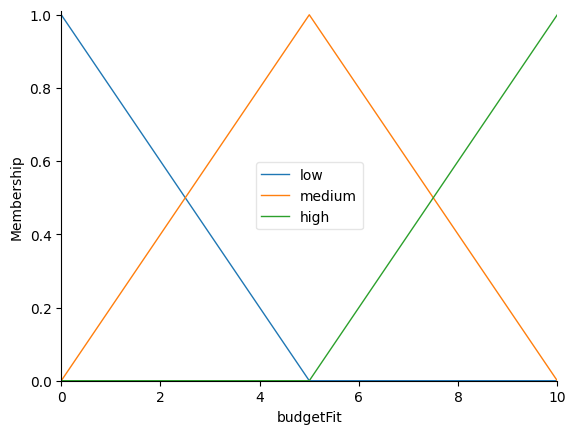

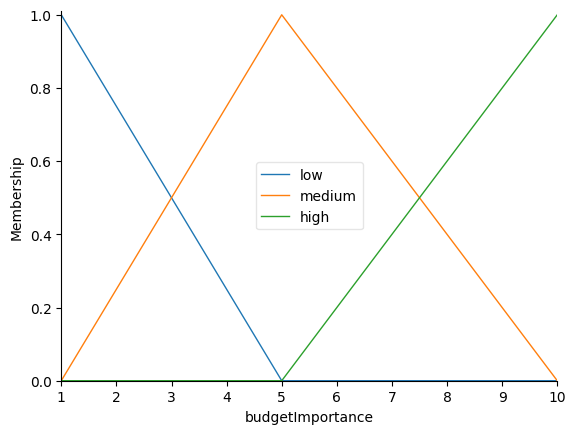

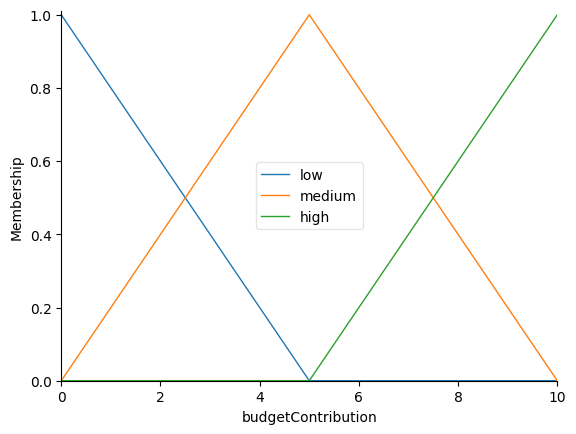

In [26]:
# Membership functions (identical for all criteria,  here for budget)
budget_system = contribution_systems["budget"]
budget_system["fit"].view()
budget_system["importance"].view()
budget_system["contribution"].view()

### Run a criterion system
Defuzzification (centroid) squeezes the output into roughly 1.7–8.3, because the outer triangles never reach 0 or 10.
So each contribution is rescaled to 0–10, using the worst and best case at maximum importance of the same system.

In [28]:
def run_contribution_system(name, fit_score, importance):
    """Run the fuzzy system of one criterion and return the raw contribution"""
    sim = contribution_systems[name]["sim"]
    sim.input[f"{name}Fit"] = fit_score
    sim.input[f"{name}Importance"] = importance
    sim.compute()
    return sim.output[f"{name}Contribution"]


# Calibration: worst case (fit 0) and best case (fit 10) at maximum importance
contribution_range = {
    name: (run_contribution_system(name, 0, 10), run_contribution_system(name, 10, 10))
    for name in importances
}


def calculate_contributions(fits):
    """Contribution (0-10) of every criterion for one event"""
    contributions = {}
    for name, importance in importances.items():
        raw = run_contribution_system(name, fits[f"{name}Fit"], importance)
        worst, best = contribution_range[name]
        contributions[name] = 10 * (raw - worst) / (best - worst)
    return contributions

## 6. Final fuzzy system: contribution score → match
The six contributions are averaged

**Input:** contribution score (0–10) **→ Output:** event match (0–100 %)

Rules:
- If the contribution score is low, the event match is low.
- If the contribution score is medium, the event match is medium.
- If the contribution score is high, the event match is high.

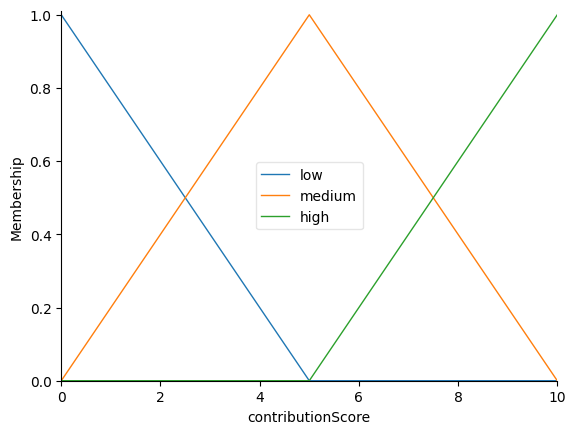

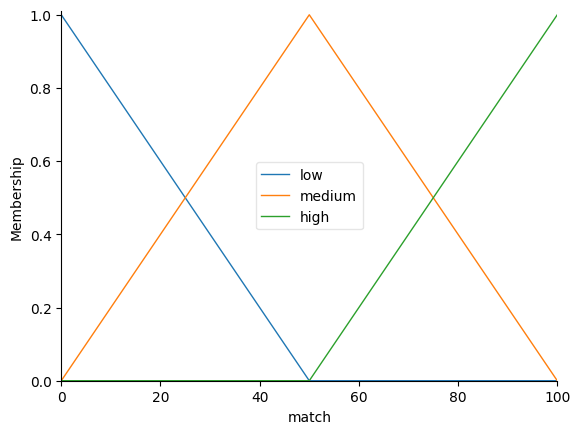

In [29]:
# Antecedent - average contribution
contributionScore = ctrl.Antecedent(np.linspace(0, 10, 101), 'contributionScore')

# Consequent - event match in percent
match = ctrl.Consequent(np.linspace(0, 100, 101), 'match')
match.defuzzify_method = 'centroid'

# Triangular membership functions
add_triangular_terms(contributionScore, 0)
match['low']    = fuzz.trimf(match.universe, [0, 0, 50])
match['medium'] = fuzz.trimf(match.universe, [0, 50, 100])
match['high']   = fuzz.trimf(match.universe, [50, 100, 100])

# Rules
match_ctrl = ctrl.ControlSystem([
    ctrl.Rule(contributionScore['low'],    match['low']),
    ctrl.Rule(contributionScore['medium'], match['medium']),
    ctrl.Rule(contributionScore['high'],   match['high']),
])

contributionScore.view()
match.view()

In [30]:
def calculate_fuzzy_match(contributions):
    """Average the contributions and run the final fuzzy system"""
    score = sum(contributions.values()) / len(contributions)

    match_sim = ctrl.ControlSystemSimulation(match_ctrl)
    match_sim.input['contributionScore'] = score
    match_sim.compute()
    return score, match_sim.output['match']

## 7. Evaluate all events
For every event: six fit scores → six fuzzy contributions → average → fuzzy match.

In [31]:
results = []

for event in events:
    # Calculate fit scores
    fits = calculate_event_fits(event)

    # Fuzzy system per criterion (fit x importance -> contribution)
    contributions = calculate_contributions(fits)

    # Final fuzzy system (average contribution -> match)
    score, final_match = calculate_fuzzy_match(contributions)

    # Results
    results.append({
        "Event":        event["name"],
        "Date":         round(contributions["date"], 2),
        "Time":         round(contributions["time"], 2),
        "Distance":     round(contributions["distance"], 2),
        "Budget":       round(contributions["budget"], 2),
        "Group size":   round(contributions["groupSize"], 2),
        "Energy":       round(contributions["energy"], 2),
        "Score":        round(score, 2),
        "Match (%)":    round(final_match, 2),
    })

### Ranking
Columns *Date* to *Energy* are the contributions (0–10) of each criterion.

In [32]:
# Ranking
ranking = sorted(results, key=lambda r: r["Match (%)"], reverse=True)

# Print
columns = list(ranking[0].keys())
widths = {c: max(len(c), *(len(f"{r[c]}") for r in ranking)) for c in columns}

header = "  ".join(c.ljust(widths[c]) for c in columns)
print(header)
print("-" * len(header))

for row in ranking:
    print("  ".join(
        f"{row[c]}".ljust(widths[c]) if c == "Event" else f"{row[c]}".rjust(widths[c])
        for c in columns
    ))

Event                Date  Time  Distance  Budget  Group size  Energy  Score  Match (%)
---------------------------------------------------------------------------------------
Cinema Night         10.0  6.52      10.0    10.0        9.92    4.95   8.56      62.98
Rock Concert         10.0  9.71       0.0    10.0        9.92    6.12   7.62      56.59
Dinner with Friends  10.0  7.49       0.0    10.0        9.92    6.12   7.25       54.8
Escape Room          10.0  6.52       0.0    6.32        9.92    7.07   6.64      52.53
Hiking Trip          5.89  0.29       0.0    10.0        9.92    7.07   5.53      50.27
